In [1]:
# Data Processing
import pandas as pd
import numpy as np
# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
# Data Preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from imblearn.over_sampling import SMOTE
import shap
import joblib
import streamlit as st

/home/sujon/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data= pd.read_csv("customer_churn_dataset-training-master.csv")
data.head(10)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0
5,8.0,51.0,Male,33.0,25.0,9.0,26.0,Premium,Annual,129.0,8.0,1.0
6,9.0,58.0,Female,49.0,12.0,3.0,16.0,Standard,Quarterly,821.0,24.0,1.0
7,10.0,55.0,Female,37.0,8.0,4.0,15.0,Premium,Annual,445.0,30.0,1.0
8,11.0,39.0,Male,12.0,5.0,7.0,4.0,Standard,Quarterly,969.0,13.0,1.0
9,12.0,64.0,Female,3.0,25.0,2.0,11.0,Standard,Quarterly,415.0,29.0,1.0


In [3]:
data.shape

(440833, 12)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  str    
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  str    
 8   Contract Length    440832 non-null  str    
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), str(3)
memory usage: 48.3 MB


In [5]:
data.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [6]:
data.isnull().sum()

CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

In [7]:
data.dropna(inplace= True)

/tmp/ipykernel_90697/1335109364.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(inplace= True)


In [8]:
data.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
data["Churn"].value_counts()

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64

In [11]:
missing = pd.DataFrame({
    "Missing_Count": data.isnull().sum(),
    "Missing_Percentage": data.isnull().mean()*100
})
display(missing.sort_values(by="Missing_Percentage",ascending= False))

,Missing_Count,Missing_Percentage
CustomerID,0,0.0
Age,0,0.0
Gender,0,0.0
Tenure,0,0.0
Usage Frequency,0,0.0
Support Calls,0,0.0
Payment Delay,0,0.0
Subscription Type,0,0.0
Contract Length,0,0.0
Total Spend,0,0.0


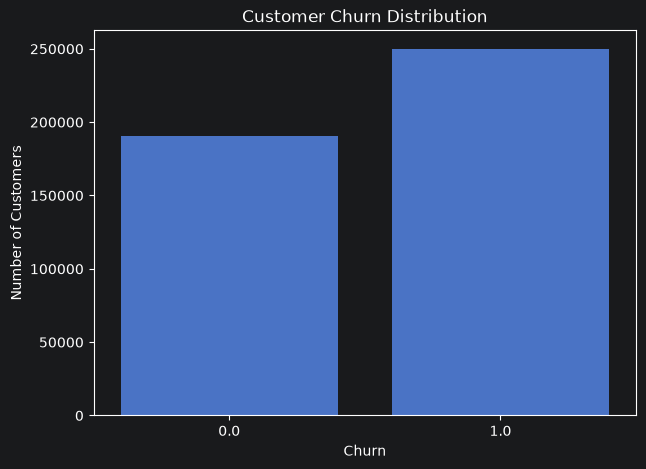

In [12]:
plt.figure(figsize=(7,5))
sns.countplot(data=data, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

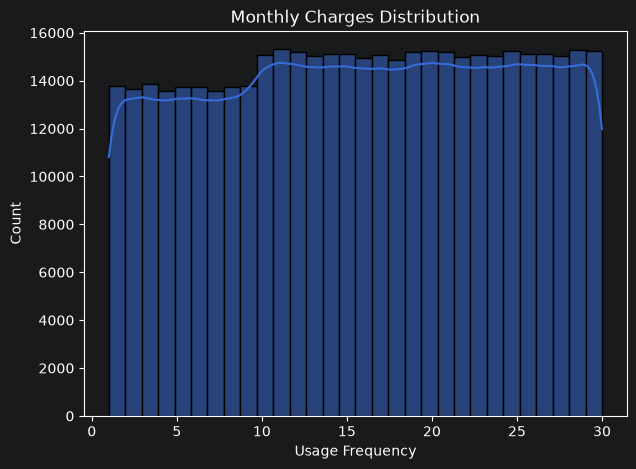

In [13]:
plt.figure(figsize=(7,5))
sns.histplot(
    data = data, x="Usage Frequency", bins= 30, kde= True
)
plt.title("Monthly Charges Distribution")
plt.show()

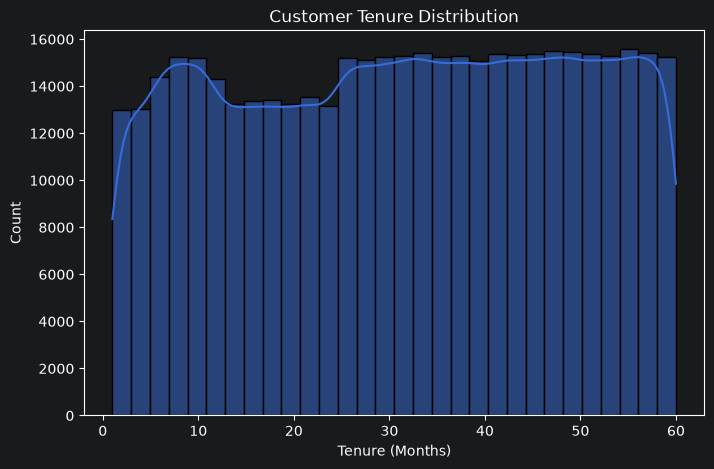

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="Tenure",
    bins=30,
    kde=True
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")

plt.show()

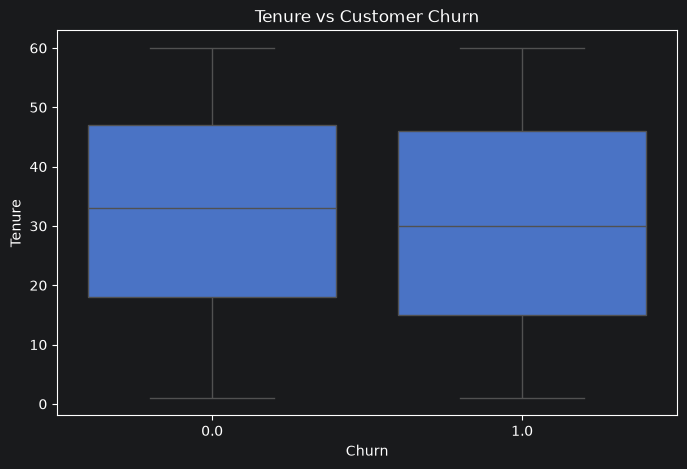

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Churn",
    y="Tenure"
)

plt.title("Tenure vs Customer Churn")
plt.show()

In [16]:

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data["Churn"] = le.fit_transform(data["Churn"])
data = data.drop(columns=["CustomerID"],errors ="ignore")
x = data.drop(columns=["Churn"])
y = data["Churn"]
print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (440832, 10)
Target shape: (440832,)


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (352665, 10)
X_test: (88167, 10)
y_train: (352665,)
y_test: (88167,)


In [18]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# Sanity check: any columns left out?
unassigned = set(X_train.columns) - set(numeric_features) - set(categorical_features)
print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)
print("Unassigned Features:", list(unassigned))

Numerical Features: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical Features: ['Gender', 'Subscription Type', 'Contract Length']
Unassigned Features: []


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_features),
])

preprocessor.set_output(transform="pandas")  # returns DataFrames, not arrays

# Fit on train only, transform both
X_train_scaled = preprocessor.fit_transform(X_train)

X_test_scaled = preprocessor.transform(X_test)

print(X_train_scaled.shape, X_test_scaled.shape)
print(X_train_scaled.head())

(352665, 15) (88167, 15)
        num__Age  num__Tenure  num__Usage Frequency  num__Support Calls  \
318331  0.210377     0.855271              1.651238           -0.197156   
429062 -0.512784     0.681455              0.137056           -0.848223   
60074  -1.075242    -1.056712              1.651238            0.128377   
12759  -0.834189    -1.288467              0.835909            2.081578   
357321 -0.111028    -1.230528              0.486483           -1.173756   

        num__Payment Delay  num__Total Spend  num__Last Interaction  \
318331           -1.085320          1.300956              -0.753449   
429062            0.246158          1.478368              -0.288211   
60074            -0.116972          0.698312              -1.102379   
12759             1.335549         -2.130477               0.525957   
357321           -1.569494          0.195568               0.409648   

        cat__Gender_Female  cat__Gender_Male  cat__Subscription Type_Basic  \
318331             

#Model Evaluation

In [20]:
X_train_scaled.head()

,num__Age,num__Tenure,num__Usage Frequency,num__Support Calls,num__Payment Delay,num__Total Spend,num__Last Interaction,cat__Gender_Female,cat__Gender_Male,cat__Subscription Type_Basic,cat__Subscription Type_Premium,cat__Subscription Type_Standard,cat__Contract Length_Annual,cat__Contract Length_Monthly,cat__Contract Length_Quarterly
318331,0.210377,0.855271,1.651238,-0.197156,-1.085320,1.300956,-0.753449,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
429062,-0.512784,0.681455,0.137056,-0.848223,0.246158,1.478368,-0.288211,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
60074,-1.075242,-1.056712,1.651238,0.128377,-0.116972,0.698312,-1.102379,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
12759,-0.834189,-1.288467,0.835909,2.081578,1.335549,-2.130477,0.525957,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
357321,-0.111028,-1.230528,0.486483,-1.173756,-1.569494,0.195568,0.409648,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train_scaled, y_train)
dt_pred = dt_model.predict(X_test_scaled)

rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

In [22]:
from sklearn.metrics import confusion_matrix, classification_report

predictions = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "KNN": knn_pred,
}

for name, y_pred in predictions.items():
    print(f"\n{name} - Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print(f"\n{name} - Classification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Not Churn", "Churn"],
        zero_division=0
    ))


Logistic Regression - Confusion Matrix:
[[34492  3675]
 [ 5726 44274]]

Logistic Regression - Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.86      0.90      0.88     38167
       Churn       0.92      0.89      0.90     50000

    accuracy                           0.89     88167
   macro avg       0.89      0.89      0.89     88167
weighted avg       0.89      0.89      0.89     88167


Decision Tree - Confusion Matrix:
[[38164     3]
 [ 3874 46126]]

Decision Tree - Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.91      1.00      0.95     38167
       Churn       1.00      0.92      0.96     50000

    accuracy                           0.96     88167
   macro avg       0.95      0.96      0.96     88167
weighted avg       0.96      0.96      0.96     88167


Random Forest - Confusion Matrix:
[[38164     3]
 [   59 49941]]

Random Forest - Classification Report:
              pr

In [23]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

# Tune on a 30k sample, not the full data
X_tune = X_train_scaled.sample(30000, random_state=42)
y_tune = y_train.loc[X_tune.index]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = "f1"

# Logistic Regression (20 -> 6 candidates)scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid={"C": [0.1, 1, 10], "class_weight": [None, "balanced"]},
    cv=cv, scoring=scoring, n_jobs=-1, verbose=1
)
lr_grid.fit(X_tune, y_tune)

# Decision Tree (remove the fixed max_depth=4, the grid sets it)
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={
        "max_depth": [3, 5, 7, 10],
        "min_samples_leaf": [1, 5, 10],
        "criterion": ["gini", "entropy"],
    },
    cv=cv, scoring=scoring, n_jobs=-1, verbose=1
)
dt_grid.fit(X_tune, y_tune)

# Random Forest (n_jobs=1 inside, parallel only outside)
rf_grid = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions={
        "n_estimators": [100, 200],
        "max_depth": [5, 10, 15],
        "min_samples_leaf": [1, 2, 5],
        "max_features": ["sqrt", "log2"],
    },
    n_iter=8, cv=cv, scoring=scoring, random_state=42, n_jobs=-1, verbose=1
)
rf_grid.fit(X_tune, y_tune)

# KNN (smaller grid, euclidean only)
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={"n_neighbors": [5, 9, 15], "weights": ["uniform", "distance"]},
    cv=cv, scoring=scoring, n_jobs=-1, verbose=1
)
knn_grid.fit(X_tune, y_tune)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Fitting 3 folds for each of 24 candidates, totalling 72 fits
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Fitting 3 folds for each of 6 candidates, totalling 18 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [5, 9, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_di

In [24]:
for name, g in [("Logistic Regression", lr_grid), ("Decision Tree", dt_grid),
                ("Random Forest", rf_grid), ("KNN", knn_grid)]:
    print(f"{name}\n  Best params: {g.best_params_}\n  Best CV {scoring}: {g.best_score_:.4f}\n")

Logistic Regression
  Best params: {'C': 10, 'class_weight': 'balanced'}
  Best CV f1: 0.9048

Decision Tree
  Best params: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1}
  Best CV f1: 0.9967

Random Forest
  Best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 15}
  Best CV f1: 0.9923

KNN
  Best params: {'n_neighbors': 5, 'weights': 'distance'}
  Best CV f1: 0.9366



In [25]:
tuned_predictions = {
    "Logistic Regression (tuned)": lr_grid.best_estimator_.predict(X_test_scaled),
    "Decision Tree (tuned)": dt_grid.best_estimator_.predict(X_test_scaled),
    "Random Forest (tuned)": rf_grid.best_estimator_.predict(X_test_scaled),
    "KNN (tuned)": knn_grid.best_estimator_.predict(X_test_scaled),
}

for name, y_pred in tuned_predictions.items():
    print(f"\n{name} - Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print(f"\n{name} - Classification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=["Not Churn", "Churn"],
        zero_division=0
    ))


Logistic Regression (tuned) - Confusion Matrix:
[[35321  2846]
 [ 6469 43531]]

Logistic Regression (tuned) - Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.85      0.93      0.88     38167
       Churn       0.94      0.87      0.90     50000

    accuracy                           0.89     88167
   macro avg       0.89      0.90      0.89     88167
weighted avg       0.90      0.89      0.89     88167


Decision Tree (tuned) - Confusion Matrix:
[[38160     7]
 [  250 49750]]

Decision Tree (tuned) - Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.99      1.00      1.00     38167
       Churn       1.00      0.99      1.00     50000

    accuracy                           1.00     88167
   macro avg       1.00      1.00      1.00     88167
weighted avg       1.00      1.00      1.00     88167


Random Forest (tuned) - Confusion Matrix:
[[38146    21]
 [  568 49432]]

Random Forest (

In [26]:
from sklearn.metrics import accuracy_score, f1_score

before = {"Logistic Regression": lr_pred, "Decision Tree": dt_pred,
          "Random Forest": rf_pred, "KNN": knn_pred}
after = {k.replace(" (tuned)", ""): v for k, v in tuned_predictions.items()}

compare = pd.DataFrame({
    name: {
        "Acc before": accuracy_score(y_test, before[name]),
        "Acc after": accuracy_score(y_test, after[name]),
        "F1 before": f1_score(y_test, before[name]),
        "F1 after": f1_score(y_test, after[name]),
    } for name in before
}).T
print(compare.round(4))

                     Acc before  Acc after  F1 before  F1 after
Logistic Regression      0.8934     0.8943     0.9040    0.9033
Decision Tree            0.9560     0.9971     0.9597    0.9974
Random Forest            0.9993     0.9933     0.9994    0.9941
KNN                      0.9597     0.9350     0.9632    0.9394


In [30]:
import joblib

# 1. Train your models (example names)
# lr_model.fit(X_train, y_train)
# dt_model.fit(X_train, y_train)
# rf_model.fit(X_train, y_train)
# knn_model.fit(X_train, y_train)


joblib.dump(dt_model, 'dt_model.pkl')
joblib.dump(rf_model, 'Rf_model.pkl')
joblib.dump(knn_model, 'knn_model.pkl')

# Initialize and fit your scaler on your feature data (X_train)


# Now saving will work
joblib.dump(preprocessor, 'scalers.pkl')
print("All models successfully saved as .pkl files!")

All models successfully saved as .pkl files!
